# 07 Validation of the mined cascades against the ground truth (SIMULATED)

**This is the only notebook that reads the ground truth** (`delay_attribution` and the ground-truth cascade tables, with `validation_only=True`). The mining method is **frozen**: it was set on 2024-01-01..2024-10-31 and is not changed after seeing anything here. Where something is clearly wrong this notebook reports it and proposes a fix as a separate "v2" without altering the v1 results.

**Window:** 2025-01-01 .. 2025-08-31 of the medium run (the ground-truth cascades exist for the 2025 run only; this window lies inside the frozen application window). Validation fold 2 (Sep-Oct 2025) and the test window are not used.

**What "truth" means here.** At the arrival row of a section's exit station the simulator labels how many minutes were added and why: a leading train held the follower (section wait), the train was held for a faster train that arrives after it (yield), an incident, a disruption, a freight blocker, a halt extension, weather. The mined links say "the late train that entered just ahead of this one delayed it"; they can only match section waits.

In [1]:
import os, sys, warnings
os.chdir("..") if os.path.basename(os.getcwd()) == "notebooks" else None
sys.path.insert(0, ".")
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.analysis import mining_pipeline as mp, validation as va, eda
from src.graph.timetable import load_timetable
from src.graph.groundtruth import load_groundtruth

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "font.size": 9})
BLUE, ORANGE, GREEN, GREY, RED = "#1f6f9f", "#d98c1f", "#6a9f58", "#888888", "#b5483a"
FIG = Path("reports/figures"); FIG.mkdir(parents=True, exist_ok=True)
def save(fig, name):
    fig.savefig(FIG / f"validation_{name}.png", dpi=130, bbox_inches="tight"); plt.show()
S = "  [SIMULATED]"
W = ("2025-01-01", "2025-08-31"); SCEN = "data/processed/sim/medium"
tt = load_timetable(); node_of = tt.node_of; names = tt.net.node_names
directions = {t: int(np.sign(sum(h.direction for h in sp.hops if h.kind == "section"))) for t, sp in tt.specs.items()}
inf = mp.load_saved(*W)
runs = inf["runs"][["run_id", "train", "day"]]
truth = va.load_truth_links(SCEN, *W, node_of, directions, validation_only=True)
casc_t, runs_t = load_groundtruth(SCEN, validation_only=True)
events = pd.read_parquet(Path(SCEN) / "events.parquet")
print(f"inferred: {len(inf['cascades']):,} cascades, {len(inf['passage_links']):,} section links, {len(inf['primary_events']):,} primary events")
print(f"truth rows with at least 0.5 minute added: {len(truth):,}; by cause:", truth.cause_code.map(va.NAMES).value_counts().to_dict())

inferred: 9,640 cascades, 108,651 section links, 6,728 primary events
truth rows with at least 0.5 minute added: 503,387; by cause: {'section wait (leader)': 316626, 'weather': 105706, 'yield': 35280, 'entry delay': 15524, 'incident': 11961, 'freight': 11646, 'halt extension': 6100, 'rake reuse': 279, 'disruption': 265}


## A. Link-level precision and recall

An inferred link is a follower run, the station it arrived at, and the leading train blamed. It counts as correct if the simulator recorded that train as the cause (section wait or yield) of at least 0.5 minute of added delay on that arrival.

In [2]:
pl = inf["passage_links"].merge(runs.rename(columns={"train": "t2"})[["run_id", "day"]], on="run_id")
links = pl.rename(columns={"lead_train": "leader"})[["train", "day", "to_node", "leader", "gap_act", "added"]]
pr_all = va.link_precision_recall(links, truth, codes=(4, 5)); pr_wait = va.link_precision_recall(links, truth, codes=(4,))
print("against section waits and yields:", {k: round(v, 3) if isinstance(v, float) else v for k, v in pr_all.items()})
print("against section waits only      :", {k: round(v, 3) if isinstance(v, float) else v for k, v in pr_wait.items()})
print("\nrecall by true cause (links recovered, follower + station + leader train):"); print(va.recall_by_cause(links, truth).round(3).to_string(index=False))
print("\ninferred links that are not correct, by what the truth says:"); print(va.false_positive_breakdown(links, truth).to_string())
links["bin"] = pd.cut(links.gap_act, [0, 2, 4, 6, 100], right=False)
ok = links.merge(truth[truth.cause_code.isin((4,))][["train", "day", "to_node", "cause_train"]].rename(columns={"cause_train": "leader"}).drop_duplicates().assign(correct=True), on=["train", "day", "to_node", "leader"], how="left")
print("\nprecision by actual gap to the leader (minutes):"); print(ok.groupby("bin", observed=True).correct.agg(links="size", precision=lambda s: s.notna().mean()).round(3).to_string())

against section waits and yields: {'inferred': 108651, 'true': 348853, 'correct': 87902, 'precision': 0.809, 'recall': 0.252}
against section waits only      : {'inferred': 108651, 'true': 316626, 'correct': 86870, 'precision': 0.8, 'recall': 0.274}

recall by true cause (links recovered, follower + station + leader train):


 cause_code                 cause  true_links  recovered  recall
          1              incident       11961          0   0.000
          2            disruption         265          0   0.000
          3               weather      105706          0   0.000
          4 section wait (leader)      316626      86870   0.274
          5                 yield       35266       1811   0.051
          6               freight       11603          0   0.000
          7            rake reuse         279          0   0.000
          8        halt extension        6100          0   0.000
          9           entry delay       15524          0   0.000

inferred links that are not correct, by what the truth says:


wrong leader (another train was the cause)    18809
caused by something other than a train         1429
no label at that row                            511



precision by actual gap to the leader (minutes):
          links  precision
bin                       
[0, 2)    25737      0.351
[2, 4)     8723      0.890
[4, 6)    73655      0.950
[6, 100)    536      0.134


## B. What really caused the inferred primary events

Each inferred primary event (a section adding at least 15 minutes with no late leader to explain it) is matched to the cause the simulator labelled with the most added minutes for that run and section.

cause
yield                    0.380
incident                 0.282
section wait (leader)    0.280
freight                  0.041
disruption               0.010
halt extension           0.005
weather                  0.001
total inferred primary events: 6728


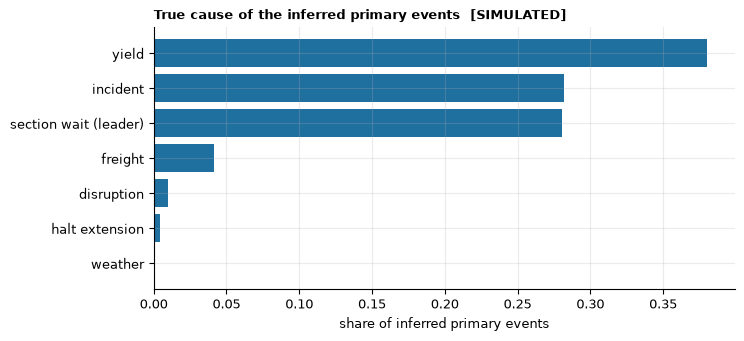

In [3]:
pe = inf["primary_events"].merge(runs[["run_id", "day"]], on="run_id")
counts, j = va.origin_cause_breakdown(pe, truth)
print((counts / counts.sum()).round(3).to_string()); print("total inferred primary events:", int(counts.sum()))
fig, ax = plt.subplots(figsize=(7.5, 3.4))
cs_ = (counts / counts.sum()).sort_values(); ax.barh(cs_.index, cs_.values, color=BLUE); ax.set_xlabel("share of inferred primary events")
ax.set_title("True cause of the inferred primary events" + S, loc="left", fontweight="bold", fontsize=9); save(fig, "01_primary_event_causes")
mins = j.groupby("cause").apply(lambda g: g.added.sum() if "added" in g else np.nan, include_groups=False)

## C. Cascade matching and size

Inferred cascades started by a primary event are matched to true section events (incident, freight blocker, disruption) by train, section and start time (5 minutes). The comparable true size counts only runs that received at least 2 minutes of their delay from the event (the mining links a follower only if it adds 2 minutes).

true section incidents in the window: 12,045 (1,879 of at least 15 minutes); inferred primary-origin cascades: 3,888
recall of large incidents (>= 15 min) by an inferred primary origin: 0.607
share of inferred primary-origin cascades that match a true incident: 0.301
matched cascades: 1,172; inferred size mean 2.77, true size mean 6.62, true size with >= 2 min 6.08


Spearman of inferred size vs true size (>=2 min): 0.376 | Pearson 0.338 | vs all true runs: 0.366
by true incident duration:
              n  inferred  true_2min
d                                   
(0, 15]       2      2.00       4.50
(15, 30]     72      2.51       5.28
(30, 60]    172      3.08       6.52
(60, 1000]  351      4.84       7.95


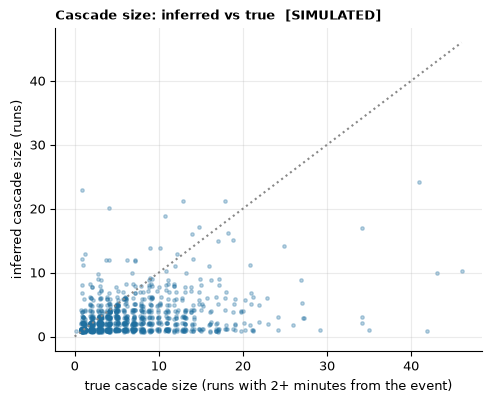

In [4]:
sec_ev = events[events.type.isin(["section_incident", "disruption_block", "disruption_signal", "freight"])].copy()
sec_ev = sec_ev[(sec_ev.start_min >= pd.Timestamp(W[0]).normalize().value / 6e10 * 0) ]
lo, hi = (pd.Timestamp(W[0]) - pd.Timestamp("2025-01-01")).days * 1440.0, (pd.Timestamp(W[1]) - pd.Timestamp("2025-01-01")).days * 1440.0 + 1440.0
inc = events[(events.type == "section_incident") & (events.start_min >= lo) & (events.start_min < hi)]
prim = inf["cascades"][inf["cascades"].origin_type == "primary"]
m = va.match_origins(prim, inc, tol=5.0)
big = inc[inc.duration_min >= 15]
print(f"true section incidents in the window: {len(inc):,} ({len(big):,} of at least 15 minutes); inferred primary-origin cascades: {len(prim):,}")
mb = va.match_origins(prim, big, tol=5.0)
print(f"recall of large incidents (>= 15 min) by an inferred primary origin: {mb.event_id.nunique() / len(big):.3f}")
print(f"share of inferred primary-origin cascades that match a true incident: {len(m) / len(prim):.3f}")
tr_size = casc_t.set_index("origin_event_id").size_runs_delayed
rn = runs_t[runs_t.delay_minutes_added >= 2].groupby("origin_event_id").size()
mm = m.assign(true_size=m.event_id.map(tr_size), true_size_2min=m.event_id.map(rn).fillna(0))
mm = mm[mm.true_size.notna()]
print(f"matched cascades: {len(mm):,}; inferred size mean {mm.size_runs.mean():.2f}, true size mean {mm.true_size.mean():.2f}, true size with >= 2 min {mm.true_size_2min.mean():.2f}")
print("Spearman of inferred size vs true size (>=2 min): %.3f | Pearson %.3f | vs all true runs: %.3f" % (
    va.spearman(mm.size_runs, mm.true_size_2min), mm.size_runs.corr(mm.true_size_2min), va.spearman(mm.size_runs, mm.true_size)))
print("by true incident duration:"); print(mm.assign(d=pd.cut(mm.duration_min, [0, 15, 30, 60, 1000])).groupby("d", observed=True).agg(n=("size_runs", "size"), inferred=("size_runs", "mean"), true_2min=("true_size_2min", "mean")).round(2).to_string())
fig, ax = plt.subplots(figsize=(5.5, 4.2))
ax.scatter(mm.true_size_2min + np.random.default_rng(0).uniform(-.25, .25, len(mm)), mm.size_runs + np.random.default_rng(1).uniform(-.25, .25, len(mm)), s=6, alpha=0.3, color=BLUE)
mx = max(mm.true_size_2min.max(), mm.size_runs.max()); ax.plot([0, mx], [0, mx], color=GREY, ls=":"); ax.set_xlabel("true cascade size (runs with 2+ minutes from the event)"); ax.set_ylabel("inferred cascade size (runs)")
ax.set_title("Cascade size: inferred vs true" + S, loc="left", fontweight="bold", fontsize=9); save(fig, "02_cascade_size")

## D. Ranking of origin sections

                                                                                         comparison  Spearman
                                           origin frequency vs true incidents >= 15 min per section     0.694
                                           size triggered vs true cascade size of matched incidents     0.745
primary delay minutes vs true minutes generated by incident / disruption / freight / halt extension     0.691
                                                         origin frequency vs true generated minutes     0.606

top sections, true incident count: ['SKB-KAA', 'CNB-CNBI', 'ETW-EKL', 'GOY-CNB', 'SB-ETW', 'MNR-SKB', 'TDL-HNG', 'PRYG-KCN']
top sections, inferred origin frequency: ['ETW-EKL', 'CNB-CNBI', 'ARW-JEP', 'TDL-HNG', 'PATA-PHD', 'PHD-KNS', 'MNR-SKB', 'FZD-MNR']
overlap of the two top-8 lists: 4


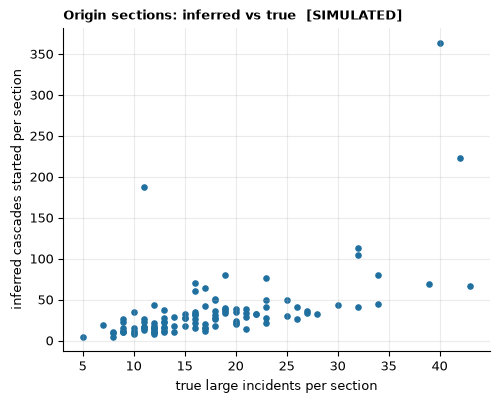

In [5]:
sec_n = 107
true_inc_count = big.groupby("section").size().reindex(range(sec_n)).fillna(0)
true_inc_size = (mm.groupby("section").true_size_2min.sum()).reindex(range(sec_n)).fillna(0)
gen = truth[truth.cause_code.isin((1, 2, 6, 8))].groupby("sec").new_minutes.sum().reindex(range(sec_n)).fillna(0)
cr_ = inf["critical_sections"].set_index("sec").reindex(range(sec_n))
rows = [("origin frequency vs true incidents >= 15 min per section", cr_.origin_freq, true_inc_count),
        ("size triggered vs true cascade size of matched incidents", cr_.size_triggered, true_inc_size),
        ("primary delay minutes vs true minutes generated by incident / disruption / freight / halt extension", cr_.primary_minutes, gen),
        ("origin frequency vs true generated minutes", cr_.origin_freq, gen)]
tab = pd.DataFrame([{"comparison": n, "Spearman": va.spearman(a, b)} for n, a, b in rows])
print(tab.round(3).to_string(index=False))
ti, tg = true_inc_count.sort_values(ascending=False).head(8), cr_.origin_freq.sort_values(ascending=False).head(8)
print("\ntop sections, true incident count:", [(names[s] + "-" + names[s + 1]) for s in ti.index]); print("top sections, inferred origin frequency:", [(names[s] + "-" + names[s + 1]) for s in tg.index])
print("overlap of the two top-8 lists:", len(set(ti.index) & set(tg.index)))
fig, ax = plt.subplots(figsize=(5.5, 4.2)); ax.scatter(true_inc_count, cr_.origin_freq, s=14, color=BLUE)
ax.set_xlabel("true large incidents per section"); ax.set_ylabel("inferred cascades started per section"); ax.set_title("Origin sections: inferred vs true" + S, loc="left", fontweight="bold", fontsize=9); save(fig, "03_origin_sections")

## E. Contagion coefficients against the true share of delay caused by other trains

True share per section and direction: minutes added by a leading train (section wait) or by yielding, divided by all minutes generated on the section (leader, yield, incident, disruption, weather, freight, halt extension). The mined counterpart is the explained share rho (added delay a late leader accounts for), and the pass-on ratio.

sections compared: 214
true share caused by other trains: overall 0.791, per section median 0.776 (range 0.24-0.93)
mined explained share rho: median 0.485 (range 0.13-0.76)
Spearman of rho        with the true share:  0.625 (n=214)


Spearman of A_all      with the true share:  0.294 (n=214)
Spearman of beta       with the true share: -0.045 (n=214)
Spearman of A_primary  with the true share:  0.143 (n=77)
Spearman of c          with the true share:  0.013 (n=214)


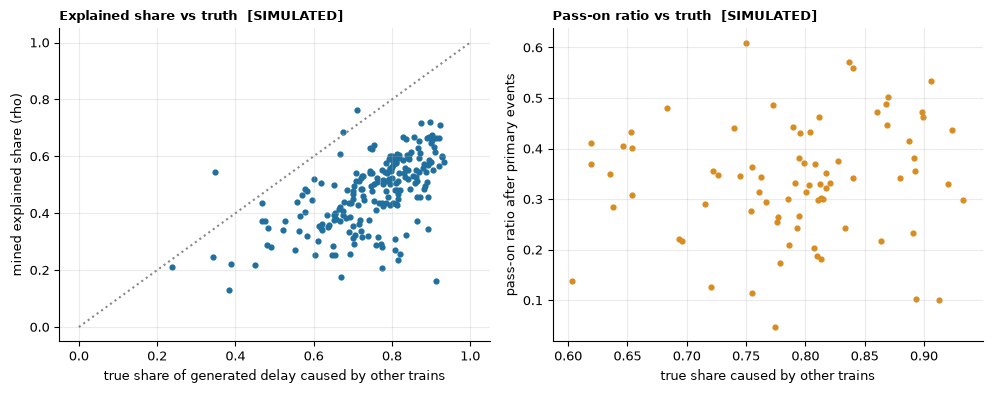

In [6]:
ts = va.other_train_share(truth)
c = inf["contagion"].merge(ts, on=["sec", "dir"], how="inner")
print("sections compared:", len(c))
print("true share caused by other trains: overall %.3f, per section median %.3f (range %.2f-%.2f)" % (
    truth[truth.cause_code.isin(va.OTHER_TRAIN)].new_minutes.sum() / truth[truth.cause_code.isin(va.GENERATED + va.OTHER_TRAIN)].new_minutes.sum(), c.true_other_share.median(), c.true_other_share.min(), c.true_other_share.max()))
print("mined explained share rho: median %.3f (range %.2f-%.2f)" % (c.rho.median(), c.rho.min(), c.rho.max()))
for col in ("rho", "A_all", "beta", "A_primary", "c"):
    d = c.dropna(subset=[col]); print(f"Spearman of {col:10s} with the true share: {va.spearman(d[col], d.true_other_share):6.3f} (n={len(d)})")
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(c.true_other_share, c.rho, s=12, color=BLUE); axes[0].plot([0, 1], [0, 1], color=GREY, ls=":"); axes[0].set_xlabel("true share of generated delay caused by other trains"); axes[0].set_ylabel("mined explained share (rho)")
axes[0].set_title("Explained share vs truth" + S, loc="left", fontweight="bold", fontsize=9)
d = c.dropna(subset=["A_primary"]); axes[1].scatter(d.true_other_share, d.A_primary, s=12, color=ORANGE); axes[1].set_xlabel("true share caused by other trains"); axes[1].set_ylabel("pass-on ratio after primary events")
axes[1].set_title("Pass-on ratio vs truth" + S, loc="left", fontweight="bold", fontsize=9); plt.tight_layout(); save(fig, "04_contagion_vs_truth")

## F. Where the method fails

Rake links (a late train delaying the next service of its rake) are checked separately from section links, and the main failure modes are summarised from the numbers above.

In [7]:
lk = inf["links"]; rk = lk[lk.cause == 1]
runs_i = inf["runs"].set_index("run_id")
rake_inf = pd.DataFrame({"train": runs_i.loc[rk.child_run_id, "train"].to_numpy(), "day": runs_i.loc[rk.child_run_id, "day"].to_numpy(),
                         "leader": runs_i.loc[rk.parent_run_id, "train"].to_numpy(), "to_node": -1})
rake_true = truth[truth.cause_code == 7].assign(to_node=-1)
print("rake links: inferred %d, true %d" % (len(rake_inf), rake_true[["train", "day", "cause_train"]].drop_duplicates().shape[0]), {k: round(v, 3) if isinstance(v, float) else v for k, v in va.link_precision_recall(rake_inf, rake_true, codes=(7,)).items()})
ext = inf["cascades"][inf["cascades"].origin_type == "external_entry"]
ent = events[(events.type == "entry_delay") & (events.start_min >= lo) & (events.start_min < hi)]
me = ext.assign(origin_sec=-1).merge(ent.assign(section=-1)[["event_id", "train", "section", "start_min"]], left_on=["origin_train", "origin_sec"], right_on=["train", "section"])
me = me[(me.origin_time - me.start_min).abs() <= 120]
print("external-entry cascades:", len(ext), "| matched to a true entry-delay event of the same train within 2 hours:", me.origin_run_id.nunique(), "| true entry delays >= 15 min:", int((ent.duration_min >= 15).sum()))
seq = truth[truth.cause_code == 5]
print("\nyields (a train held for a faster one behind it): true %d rows; the leader rule cannot find them because the cause enters after the held train" % len(seq))
print("shares of true added minutes by cause in the window:", (truth.groupby("cause_code").new_minutes.sum() / truth.new_minutes.sum()).rename(index=va.NAMES).round(3).to_dict())

rake links: inferred 225, true 279 {'inferred': 225, 'true': 279, 'correct': 116, 'precision': 0.516, 'recall': 0.416}


external-entry cascades: 5752 | matched to a true entry-delay event of the same train within 2 hours: 5674 | true entry delays >= 15 min: 5825

yields (a train held for a faster one behind it): true 35280 rows; the leader rule cannot find them because the cause enters after the held train
shares of true added minutes by cause in the window: {'incident': 0.06400000303983688, 'disruption': 0.00800000037997961, 'weather': 0.05700000002980232, 'section wait (leader)': 0.5099999904632568, 'yield': 0.15399999916553497, 'freight': 0.03200000151991844, 'rake reuse': 0.0020000000949949026, 'halt extension': 0.014000000432133675, 'entry delay': 0.1589999943971634}


## G. Proposed v2 of the primary-event rule (separate from the frozen v1)

The validation shows that more than a third of the v1 primary events are really trains held for a faster train behind them. v2 adds one observable rule (`src/analysis/mining_v2.py`): a large delay is not primary if the train ahead of it in the same section (its leader, on time) is of a higher class and entered at most G_lead minutes earlier; G_lead = 8 is calibrated from observable decision-window data only (a faster on-time leader raises the chance of a large delay for gaps up to 8 min, then the effect vanishes). **v1 results above are unchanged.** v2 was designed after seeing the 2025 validation, so its 2025 numbers are optimistic; the independent check is 2024-11-01 .. 2024-12-31, which the design did not use (the 2024 run has the same kind of labels).

In [8]:
from src.analysis import decomposition as dc, passages, mining_v2 as v2m
from src.analysis.calibrate import load_frozen
prm = load_frozen()
def evaluate(window, scen_dir):
    df, _, nodes, bounds = eda.load_window(*window, tt=tt)
    p = dc.decompose(passages.attach_leaders(passages.build_passages(df, bounds)), prm.slack_fraction); del df
    tr = va.load_truth_links(scen_dir, *window, node_of, directions, validation_only=True)
    v1, v2 = v2m.primary_v1_v2(p, prm)
    gen = tr[tr.cause_code.isin((1, 2, 6, 8)) & (tr.new_minutes >= prm.P)][["train", "day", "sec"]].drop_duplicates()
    out = {}
    for nm, flag in (("v1 (frozen)", v1), ("v2 (proposed)", v2)):
        pe = p[flag].rename(columns={"run_day": "day"})[["train", "day", "sec", "added"]]
        pe["train"] = pe.train.astype(str)
        counts, jj = va.origin_cause_breakdown(pe, tr)
        det = gen.merge(pe[["train", "day", "sec"]].drop_duplicates(), on=["train", "day", "sec"]).shape[0]
        real = counts.reindex(["incident", "disruption", "freight", "halt extension"]).fillna(0).sum() / counts.sum()
        out[nm] = {"primary events": int(counts.sum()), "share really generated (incident/disruption/freight/halt ext.)": round(float(real), 3),
                   "share that were yields": round(float(counts.get("yield", 0) / counts.sum()), 3), "share that were section waits": round(float(counts.get("section wait (leader)", 0) / counts.sum()), 3),
                   "recall of true generated delays >= 15 min": round(det / len(gen), 3)}
    return pd.DataFrame(out)
ev25 = evaluate(W, SCEN); print("2025-01-01..2025-08-31 (design-informed, optimistic)"); print(ev25.to_string())
ev24 = evaluate(("2024-11-01", "2024-12-31"), "data/processed/sim/medium_2024"); print("\n2024-11-01..2024-12-31 (independent check)"); print(ev24.to_string())

2025-01-01..2025-08-31 (design-informed, optimistic)
                                                                v1 (frozen)  v2 (proposed)
primary events                                                     6728.000       4087.000
share really generated (incident/disruption/freight/halt ext.)        0.338          0.479
share that were yields                                                0.380          0.075
share that were section waits                                         0.280          0.446
recall of true generated delays >= 15 min                             0.875          0.783



2024-11-01..2024-12-31 (independent check)
                                                                v1 (frozen)  v2 (proposed)
primary events                                                     1969.000       1205.000
share really generated (incident/disruption/freight/halt ext.)        0.369          0.534
share that were yields                                                0.378          0.069
share that were section waits                                         0.252          0.397
recall of true generated delays >= 15 min                             0.923          0.855


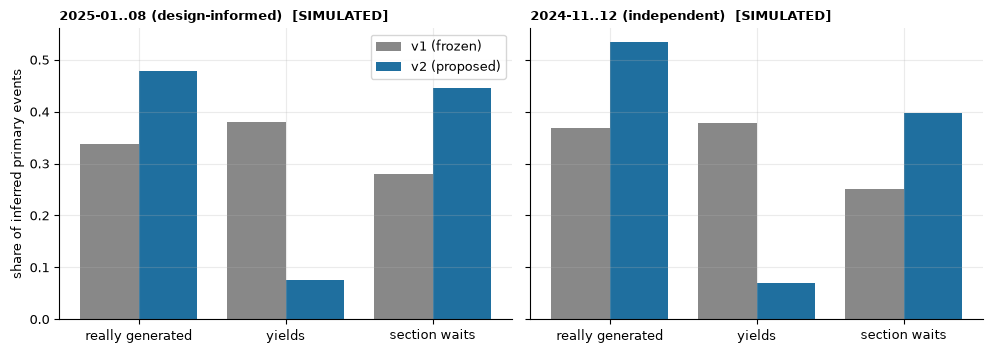

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, (ttl, ev) in zip(axes, (("2025-01..08 (design-informed)", ev25), ("2024-11..12 (independent)", ev24))):
    k = ["share really generated (incident/disruption/freight/halt ext.)", "share that were yields", "share that were section waits"]
    x = np.arange(len(k)); ax.bar(x - 0.2, ev.loc[k, "v1 (frozen)"], 0.4, color=GREY, label="v1 (frozen)"); ax.bar(x + 0.2, ev.loc[k, "v2 (proposed)"], 0.4, color=BLUE, label="v2 (proposed)")
    ax.set_xticks(x); ax.set_xticklabels(["really generated", "yields", "section waits"]); ax.set_title(ttl + S, loc="left", fontweight="bold", fontsize=9)
axes[0].set_ylabel("share of inferred primary events"); axes[0].legend(); plt.tight_layout(); save(fig, "05_v1_vs_v2")